## Findings
- Lines: 11,175,629. Unparsed: 0. Time span: 2008-11-09 20:35:18 → 2008-11-11 11:16:28 (38.7 hours).
- Levels: INFO 96.75%, WARN 3.25%, no ERROR/FATAL → anomalies are not visible from log levels.
- Every line contains exactly one block id → sessions (blocks) are clean and unambiguous.
- Blocks: 575,061, all labelled. Anomalous: 16,838 (2.93%) → strong class imbalance.
- Lines per block: normal median 19 (min 13, std 4.8); anomalous median 20 (min 2, 25th pct 4, std 12.4).
- Anomalies are two groups: truncated sessions (≤4 lines, ≥25% of anomalies, detectable by length alone)
  and normal-length sessions (detectable only through which events occur).
- Consequences: (1) template-based features are required; (2) a line-count rule is a baseline ML must beat;
  (3) report precision/recall/F1 for the anomaly class and PR-AUC, not accuracy.

In [8]:
OUT.mkdir(parents=True, exist_ok=True)
blocks.to_csv(OUT / "hdfs_block_stats.csv", index=False)
print("Saved", OUT / "hdfs_block_stats.csv")

Saved c:\Users\prajw\Downloads\Projects\cloud-log-anomaly-detection\data\processed\hdfs_block_stats.csv


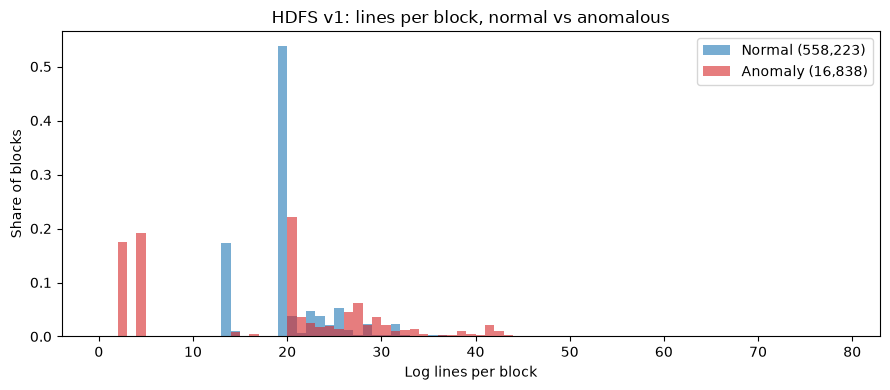

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
for label, colour in (("Normal", "tab:blue"), ("Anomaly", "tab:red")):
    subset = blocks.loc[blocks["Label"] == label, "lines"]
    ax.hist(subset, bins=range(0, 80), alpha=0.6, label=f"{label} ({len(subset):,})", color=colour, density=True)
ax.set_xlabel("Log lines per block")
ax.set_ylabel("Share of blocks")
ax.set_title("HDFS v1: lines per block, normal vs anomalous")
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
blocks = pd.DataFrame(list(lines_per_block.items()), columns=["BlockId", "lines"])
blocks = blocks.merge(labels, on="BlockId", how="outer", indicator=True)

print(blocks["_merge"].value_counts(), "\n")   # both = block in log and in labels
blocks = blocks[blocks["_merge"] == "both"].drop(columns="_merge")

print(blocks.groupby("Label")["lines"].describe().round(1))

_merge
both          575061
left_only          0
right_only         0
Name: count, dtype: int64 

            count  mean   std   min   25%   50%   75%    max
Label                                                       
Anomaly   16838.0  17.1  12.4   2.0   4.0  20.0  26.0  284.0
Normal   558223.0  19.5   4.8  13.0  19.0  19.0  20.0  298.0


In [5]:
labels = pd.read_csv(LABEL_FILE)
print(labels.head(), "\n")
counts = labels["Label"].value_counts()
print(counts)
print(f"\nAnomaly share: {100 * counts.get('Anomaly', 0) / len(labels):.2f}%  of {len(labels):,} blocks")

                    BlockId    Label
0  blk_-1608999687919862906   Normal
1   blk_7503483334202473044   Normal
2  blk_-3544583377289625738  Anomaly
3  blk_-9073992586687739851   Normal
4   blk_7854771516489510256   Normal 

Label
Normal     558223
Anomaly     16838
Name: count, dtype: int64

Anomaly share: 2.93%  of 575,061 blocks


In [4]:
print("Log levels:")
for level, count in levels.most_common():
    print(f"  {level:<6} {count:>12,}  ({100 * count / total:.2f}%)")

print("\nTop 10 components:")
for component, count in components.most_common(10):
    print(f"  {component:<45} {count:>12,}")

Log levels:
  INFO     10,812,836  (96.75%)
  WARN        362,793  (3.25%)

Top 10 components:
  dfs.FSNamesystem                                 3,700,245
  dfs.DataNode$PacketResponder                     3,413,350
  dfs.DataNode$DataXceiver                         2,518,678
  dfs.FSDataset                                    1,407,597
  dfs.DataBlockScanner                               120,046
  dfs.DataNode                                         7,002
  dfs.DataNode$DataTransfer                            6,946
  dfs.DataNode$BlockReceiver                           1,718
  dfs.PendingReplicationBlocks$PendingReplicationMonitor           47


In [3]:
LINE_RE = re.compile(r"^(\d{6}) (\d{6}) (\d+) (\w+) ([^:]+): (.*)$")
BLOCK_RE = re.compile(r"blk_-?\d+")

total = unparsed = no_block = multi_block = 0
levels, components, lines_per_block = Counter(), Counter(), Counter()
first_ts = last_ts = None

start = time.time()
with LOG_FILE.open(encoding="utf-8", errors="replace") as f:
    for line in f:
        total += 1
        match = LINE_RE.match(line)
        if not match:
            unparsed += 1
            continue
        date, clock, _pid, level, component, content = match.groups()
        levels[level] += 1
        components[component] += 1

        ts = date + clock                      # yymmddhhmmss sorts correctly as text
        first_ts = ts if first_ts is None or ts < first_ts else first_ts
        last_ts = ts if last_ts is None or ts > last_ts else last_ts

        blocks = set(BLOCK_RE.findall(content))
        if not blocks:
            no_block += 1
        elif len(blocks) > 1:
            multi_block += 1
        for block in blocks:
            lines_per_block[block] += 1

print(f"Read {total:,} lines in {time.time() - start:.0f} s")
print(f"Unparsed lines:            {unparsed:,}")
print(f"Lines without a block id:  {no_block:,}")
print(f"Lines with several blocks: {multi_block:,}")
print(f"Distinct blocks:           {len(lines_per_block):,}")

def to_datetime(ts: str) -> pd.Timestamp:
    return pd.to_datetime("20" + ts, format="%Y%m%d%H%M%S")

span = to_datetime(last_ts) - to_datetime(first_ts)
print(f"Time span: {to_datetime(first_ts)} -> {to_datetime(last_ts)}  ({span.total_seconds() / 3600:.1f} hours)")

Read 11,175,629 lines in 89 s
Unparsed lines:            0
Lines without a block id:  0
Lines with several blocks: 0
Distinct blocks:           575,061
Time span: 2008-11-09 20:35:18 -> 2008-11-11 11:16:28  (38.7 hours)


Each line: `date(yymmdd) time(hhmmss) pid level component: content`.
Block ids look like `blk_-1608999687919862906` (they can be negative). A line can mention a block id
anywhere in its content.

In [2]:
with LOG_FILE.open(encoding="utf-8", errors="replace") as f:
    for _, line in zip(range(8), f):
        print(line.rstrip())

081109 203518 143 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.19.102:54106 dest: /10.250.19.102:50010
081109 203518 35 INFO dfs.FSNamesystem: BLOCK* NameSystem.allocateBlock: /mnt/hadoop/mapred/system/job_200811092030_0001/job.jar. blk_-1608999687919862906
081109 203519 143 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.10.6:40524 dest: /10.250.10.6:50010
081109 203519 145 INFO dfs.DataNode$DataXceiver: Receiving block blk_-1608999687919862906 src: /10.250.14.224:42420 dest: /10.250.14.224:50010
081109 203519 145 INFO dfs.DataNode$PacketResponder: PacketResponder 1 for block blk_-1608999687919862906 terminating
081109 203519 145 INFO dfs.DataNode$PacketResponder: PacketResponder 2 for block blk_-1608999687919862906 terminating
081109 203519 145 INFO dfs.DataNode$PacketResponder: Received block blk_-1608999687919862906 of size 91178 from /10.250.10.6
081109 203519 145 INFO dfs.DataNode$PacketResponder: Receiv

In [1]:
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Find the project root (folder containing pyproject.toml), wherever the notebook runs from
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Project root not found; open the notebook inside the project")
    ROOT = ROOT.parent

DATA = ROOT / "data" / "raw" / "HDFS_v1"
LOG_FILE = DATA / "HDFS.log"
LABEL_FILE = DATA / "preprocessed" / "anomaly_label.csv"
OUT = ROOT / "data" / "processed"

print("Log file:  ", LOG_FILE.exists(), f"{LOG_FILE.stat().st_size / 1e9:.2f} GB" if LOG_FILE.exists() else "")
print("Label file:", LABEL_FILE.exists())

Log file:   True 1.58 GB
Label file: True


# 01 — HDFS v1 dataset exploration

Goal: understand the raw HDFS log and its labels before parsing and modelling.
- Line format, log levels, components
- Number of blocks (sessions), labelled anomalies, class balance
- Lines per block for normal vs anomalous blocks
- Time span